In [41]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import sys

In [6]:
df=pd.read_csv("LibroML.csv")

In [10]:
ohe=OneHotEncoder(drop="first",sparse_output=False)

In [11]:
categorias_codificadas=ohe.fit_transform(df[["Categoria_grupo"]])

In [14]:
df_ohe=pd.DataFrame(
    categorias_codificadas,
    columns=ohe.get_feature_names_out(["Categoria_grupo"]),
    index=df.index
)

In [15]:
df_ohe

,"Categoria_grupo_Ciencia, salud y deporte",Categoria_grupo_Comics y narrativa grafica,"Categoria_grupo_Desarrollo personal, educacion y negocios","Categoria_grupo_Fantasia, ciencia ficcion y terror",Categoria_grupo_Ficcion general y humor,Categoria_grupo_Ficcion historica,"Categoria_grupo_Filosofia, religion y espiritualidad","Categoria_grupo_Historia, sociedad y biografias",Categoria_grupo_Literatura infantil y juvenil,"Categoria_grupo_Misterio, crimen y suspenso",Categoria_grupo_No ficcion general,Categoria_grupo_Poesia y clasicos,Categoria_grupo_Romance y relaciones,Categoria_grupo_Sin clasificacion tematica,Categoria_grupo_Viajes y gastronomia
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
996,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
997,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [16]:
df_final=pd.concat([df,df_ohe],axis=1)
df_final=df_final.drop(columns=["Categoria_grupo"])

In [17]:
df_final

,Titulo,Estrellas,Precios_limpios,Cantidad_palabras,"Categoria_grupo_Ciencia, salud y deporte",Categoria_grupo_Comics y narrativa grafica,"Categoria_grupo_Desarrollo personal, educacion y negocios","Categoria_grupo_Fantasia, ciencia ficcion y terror",Categoria_grupo_Ficcion general y humor,Categoria_grupo_Ficcion historica,"Categoria_grupo_Filosofia, religion y espiritualidad","Categoria_grupo_Historia, sociedad y biografias",Categoria_grupo_Literatura infantil y juvenil,"Categoria_grupo_Misterio, crimen y suspenso",Categoria_grupo_No ficcion general,Categoria_grupo_Poesia y clasicos,Categoria_grupo_Romance y relaciones,Categoria_grupo_Sin clasificacion tematica,Categoria_grupo_Viajes y gastronomia
0,A Light in the Attic,3,51.77,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,Tipping the Velvet,1,53.74,3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Soumission,1,50.10,1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Sharp Objects,4,47.82,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,Sapiens: A Brief History of Humankind,5,54.23,6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,Alice in Wonderland (Alice's Adventures in Won...,1,55.53,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
996,"Ajin: Demi-Human, Volume 1 (Ajin: Demi-Human #1)",4,57.06,7,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
997,A Spy's Devotion (The Regency Spies of London #1),5,16.97,9,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
998,1st to Die (Women's Murder Club #1),1,53.98,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [20]:
X=df_final.drop(columns=["Titulo","Estrellas"])

In [21]:
X

,Precios_limpios,Cantidad_palabras,"Categoria_grupo_Ciencia, salud y deporte",Categoria_grupo_Comics y narrativa grafica,"Categoria_grupo_Desarrollo personal, educacion y negocios","Categoria_grupo_Fantasia, ciencia ficcion y terror",Categoria_grupo_Ficcion general y humor,Categoria_grupo_Ficcion historica,"Categoria_grupo_Filosofia, religion y espiritualidad","Categoria_grupo_Historia, sociedad y biografias",Categoria_grupo_Literatura infantil y juvenil,"Categoria_grupo_Misterio, crimen y suspenso",Categoria_grupo_No ficcion general,Categoria_grupo_Poesia y clasicos,Categoria_grupo_Romance y relaciones,Categoria_grupo_Sin clasificacion tematica,Categoria_grupo_Viajes y gastronomia
0,51.77,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,53.74,3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,50.10,1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,47.82,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,54.23,6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,55.53,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
996,57.06,7,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
997,16.97,9,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
998,53.98,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [22]:
y=df["Estrellas"]

In [23]:
y

0      3
1      1
2      1
3      4
4      5
      ..
995    1
996    4
997    5
998    1
999    5
Name: Estrellas, Length: 1000, dtype: int64

In [24]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [50]:
for i in range(1,20):
    modelo_rf = RandomForestClassifier(n_estimators=100,
                                       max_depth=i,
                                       random_state=42,
                                       class_weight="balanced",
                                      min_samples_split=10,
                                      min_samples_leaf=4)
    modelo_rf.fit(X_train, y_train)
    resultado_real=modelo_rf.score(X_test,y_test)
    visual=modelo_rf.score(X_train,y_train)
    print(resultado_real,visual)

0.235 0.29
0.2 0.31625
0.225 0.3625
0.19 0.3975
0.2 0.41875
0.195 0.47125
0.205 0.48875
0.19 0.51125
0.205 0.53125
0.2 0.54375
0.215 0.555
0.205 0.57375
0.19 0.5875
0.205 0.595
0.215 0.60125
0.19 0.59875
0.225 0.61
0.22 0.62125
0.215 0.6175


In [51]:
prediccion=modelo_rf.predict(X_test)

In [52]:
cm = confusion_matrix(y_test,prediccion)

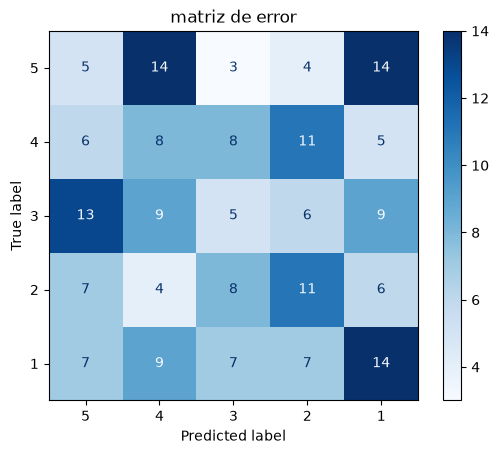

In [53]:
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=[5,4,3,2,1])
disp.plot(cmap="Blues")
plt.title("matriz de error")
plt.show()

In [42]:
sys.path.append(r"C:\Users\titos\OneDrive\Escritorio\PythonProject")
from proyecto_16 import llamada_genai

In [54]:
prompt=prompt = f"""Contexto: Se entreno al modelo con los datos limpios obtenidos de la pagina ficticia Books to Scrape (http://books.toscrape.com).
El modelo se entreno mediante un Random Forest, ya que previamente se llego a la conclusion de que los datos no tenian correlacion lineal.
Se ajustaron los hiperparametros para evitar el overfitting (principalmente min_samples_split y min_samples_leaf) y se creo una matriz de confusion, tambien se ajustaron los pesos de las variables con class_weight= balanced.

Resultados:
- Score en Test (resultado_real): {resultado_real}
- Score en Train (visual): {visual}
- Matriz de confusion:
{str(cm)}

Analiza todos estos datos y dame los insights mas relevantes para analizar este experimento."""


In [ ]:
llamada_genai(prompt)

Gemini: Como analista de datos, he evaluado el rendimiento del modelo basándome en los parámetros de entrenamiento, el algoritmo seleccionado (Random Forest) y, fundamentalmente, en la divergencia entre las métricas de entrenamiento y prueba, así como en la distribución de la matriz de confusión.

A continuación, te presento los **insights más relevantes** del experimento:

---

### 1. Evidencia Crítica de *Overfitting* Severo (Sobreajuste)
* **El contraste de métricas:** Aunque ajustaste hiperparámetros (`min_samples_split`, `min_samples_leaf`) y usaste `class_weight='balanced'`, la brecha entre el score de **Train (0.6175)** y el de **Test (0.215)** es masiva. 
* **Insight:** El modelo ha memorizado los datos de entrenamiento (patrones específicos del ruido o de muestras particulares) en lugar de generalizar. El score de Test (0.215) está muy cerca de lo que se esperaría de una **adivinación aleatoria** en un problema multiclase de 5 categorías (20%), lo que indica que el modelo actu

tu:  son las unicas variables disponibles en la pagina books to scrape, al ser una pagina para practicar y no una pagina real cuenta con muy poca informacion


Gemini: Como analista de datos, este es el tipo de revelación que **cambia por completo la perspectiva del proyecto**. Saber que las limitaciones provienen de la fuente misma de los datos (una página web didáctica con información sintética y muy acotada) nos permite pasar de un enfoque de "fallo del modelo" a un enfoque de "delimitación del problema".

Tomando en cuenta esta importante acotación, aquí te presento mi análisis actualizado y las conclusiones estratégicas:

### 1. El veredicto final: El límite de la información (*Information Entropy*)
* **Insight:** Si *Books to Scrape* solo ofrece variables básicas (título, precio, categoría, disponibilidad, calificación en estrellas y quizás UPC o tipo de impuesto), estas características simplemente **no contienen la señal matemática necesaria** para predecir con precisión la variable objetivo (asumiendo que estás intentando predecir algo complejo como la categoría exacta o un rango de precios).
* En Machine Learning hay una máxima: *"En